 <h1><center><font size="6">Առցանց խանութի ապրանքների գրադարանի կլասիֆիկացում և վիզուալիզացում</font></center></h1>
 <h1><center><font size="5">CNN with Tensorflow | Keras for Fashion MNIST</font></center></h1>


<center><img src="https://research.zalando.com/project/fashion_mnist/fashion_mnist/img/fashion-mnist-sprite.png" width="600"></img></center>


# <a id='0'>Բովանդակություն</a>

- <a href='#1'>Introduction</a>  
- <a href='#2'>Load packages (Գրադարանների բեռնում)</a>  
- <a href='#3'>Read the data (Տվյալների կարդում)</a>  
- <a href='#4'>Data exploration (Տվյալների հետախուզում)</a>
    - <a href='#41'>Class distribution (Դասերի բաշխում)</a>
    - <a href='#42'>Sample images (Նմուշների պատկերներ)</a>
- <a href='#5'>Model</a>  
    - <a href='#51'>Մոդելի պատրաստում</a>  
    - <a href='#52'>Train the model (մոդելի պարապմունք)</a>  
    - <a href='#53'>Թեստի կանխատեսման ճշգրտություն</a>   
    - <a href='#54'>Վավերացման ճշգրտություն և կորուստ</a>   
    - <a href='#55'>Մոդելին Dropout շերտերի ավելացում</a>  
    - <a href='#56'>Մոդելի վերապատրաստում</a>   
    - <a href='#57'>Վավերացման ճշգրտության և կորուստի ստուգումը նոր մոդելով</a>    
    - <a href='#58'>Կանխատեսման ճշգրտությունը նոր մոդելի հետ</a>   
- <a href='#6'>Դասակարգված պատկերների վիզուալիզացիան</a>  
    - <a href='#61'>Ճիշտ դասակարգված պատկերներ</a>   
    - <a href='#62'>Սխալ դասակարգված պատկերներ</a>   
- <a href='#9'>Օգտագիրոջ կողմից պատկերի կանխագուշակում</a>
- <a href='#7'>Եզրակացություն</a>
- <a href='#8'>Հղումներ</a>

# <a id="1">Introduction</a>  

### Dataset (Տվյալների բազա)
Fashion-MNIST-ը Zalando-ի հոդվածների պատկերների հավաքածու է, որը բաղկացած է 60,000 օրինակներից training-ի (սովորելու) հավաքածուից և 10,000 օրինակից testing-ի (թեստի) հավաքածուից: Յուրաքանչյուր օրինակ 28x28 մոխրագույն մասշտաբի պատկեր է, որը կապված է 10 դասերի label-ի (պիտակի) հետ: Zalando-ն մտադիր է Fashion-MNIST-ը ծառայել որպես մեքենայական ուսուցման ալգորիթմների չափորոշիչ MNIST-ի սկզբնական տվյալների բազայի benchmarking (ուղղակի բացթողում): Այն կիսում է նույն պատկերի չափը և կառուցվածքը սեեվերելու և թեստի բաժանումների համար:

### Բովանդակություն
Յուրաքանչյուր պատկեր ունի 28 պիքսել բարձրություն և 28 պիքսել լայնություն, ընդհանուր առմամբ 784 պիքսել:

Յուրաքանչյուր պիքսել ունի իր հետ կապված մեկ պիքսելային արժեք, որը ցույց է տալիս այդ պիքսելի թեթևությունը (lightness) կամ խավարությունը (darkness), իսկ ավելի բարձր թվերը նշանակում են ավելի մուգ: Այս պիքսել-արժեքը ամբողջ թիվ է 0-ից 255 թվերի միջև:

Սովորելու և թեստի տվյալների հավաքածուն ունի 785 սյունակ:

Առաջին սյունակը բաղկացած է դասի պիտակներից (տե՛ս վերևում) և ներկայացնում է հագուստի արտադրանքը:

Մնացած 784 սյունակները (1-785) պարունակում են փոխկապակցված պատկերի պիքսելային արժեքները։

# <a id="2">Load packages (Գրադարանների բեռնում)</a>

In [26]:
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from itertools import zip_longest
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Flatten, Conv2D, Dropout, MaxPooling2D
from IPython.display import SVG
from keras.utils import plot_model
from keras.utils import to_categorical
from keras.utils import model_to_dot
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline 
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
init_notebook_mode(connected=True)

### Parameters

In [27]:
IMG_ROWS = 28
IMG_COLS = 28
NUM_CLASSES = 10
TEST_SIZE = 0.2
RANDOM_STATE = 2018
#Model
NO_EPOCHS = 50
BATCH_SIZE = 128

IS_LOCAL = False

import os

if(IS_LOCAL):
    PATH="input/fashionmnist/"
else:
    PATH="input"
print(os.listdir(PATH))

['fashion-mnist_test.csv', 'fashion-mnist_train.csv', 't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte', 'train-images-idx3-ubyte', 'train-labels-idx1-ubyte', 'zips']


# <a id="3">Read the data (Տվյալների կարդում)</a>
Գոյություն ունեն պատկերների 10 տարբեր դասեր, ինչպիսիք են`

* **0։ T-shirt/top (շապիկ);**
* **1: Troser (Տաբատ);**
* **2. Pullover (Սվիտեր);**
* **3: Dress (Զգեստ);**
* **4. Coat (Վերարկու);**
* **5: Sandal (Սանդալ);**
* **6. Shirt (Վերնաշապիկ);**
* **7. Sneaker (Սպորտային կոշիկներ);**
* **8: Bag (Պայուսակ);**
* **9: Ankle boot (Կոճ կոշիկներ):**

Պատկերի չափերն են՝ **28x28**:

Սովորելու հավաքածուն և թեստի հավաքածուն տրված են երկու առանձին տվյալների հավաքածուներով:

In [28]:
train_file = os.path.join(PATH, "fashion-mnist_train.csv")
test_file  = os.path.join(PATH, "fashion-mnist_test.csv")

train_data = pd.read_csv(train_file)
test_data = pd.read_csv(test_file)

In [29]:
train_data.head(10)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,4,0,0,0,5,4,5,5,3,5,...,7,8,7,4,3,7,5,0,0,0
6,4,0,0,0,0,0,0,0,0,0,...,14,0,0,0,0,0,0,0,0,0
7,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,4,0,0,0,0,0,0,3,2,0,...,1,0,0,0,0,0,0,0,0,0
9,8,0,0,0,0,0,0,0,0,0,...,203,214,166,0,0,0,0,0,0,0


In [30]:
test_data.head(10)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,44,105,44,10,...,105,64,30,0,0,0,0,0,0,0
6,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,6,0,0,0,0,0,0,0,1,0,...,174,136,155,31,0,1,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,57,70,28,0,2,0,0,0,0,0


# <a id="4">Data exploration (Տվյալների հետախուզում)</a>

In [31]:
print("Fashion MNIST train -  rows:",train_data.shape[0],
      " columns:", train_data.shape[1])
print("Fashion MNIST test -  rows:",test_data.shape[0],
      " columns:", test_data.shape[1])

Fashion MNIST train -  rows: 60000  columns: 785
Fashion MNIST test -  rows: 10000  columns: 785


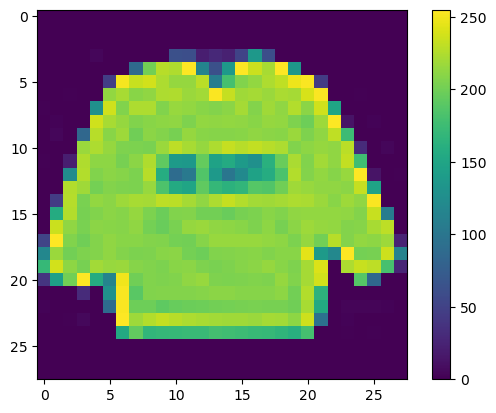

In [32]:
plt.figure()
plt.imshow(train_data.iloc[0, 1:].values.reshape(28, 28))
plt.colorbar()
plt.grid(False)
plt.show()

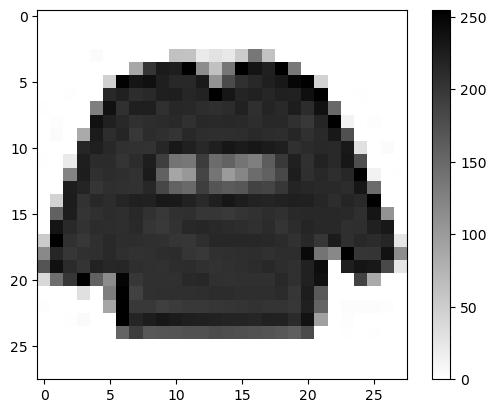

In [33]:
plt.figure()
plt.imshow(train_data.iloc[0, 1:].values.reshape(28, 28), cmap=plt.cm.binary) #cmap=plt.cm.binary for grayscale
plt.colorbar()
plt.grid(False)
plt.show()

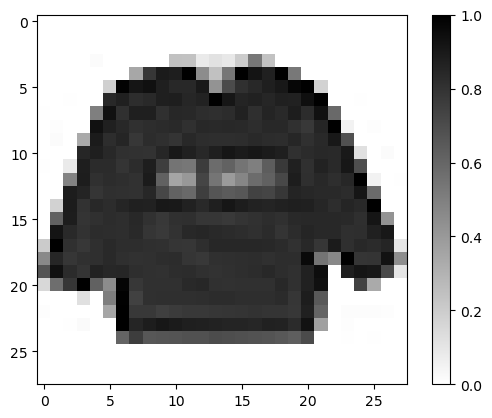

In [34]:
train_img = train_data.iloc[:, 1:].values.reshape(-1, 28, 28) / 255.0
train_lbl = train_data.iloc[:, 0].values

plt.figure()
plt.imshow(train_img[0], cmap=plt.cm.binary)
plt.colorbar()
plt.grid(False)
plt.show()

## <a id="41">Class distribution (Դասերի բաշխում)</a>
Տեսնենք, թե քանի նկար կա յուրաքանչյուր դասում: Մենք սկսում ենք training-ի հավաքածուից:

Train հավաքածու պատկերների դասի բաշխում

In [35]:
# Create a dictionary for each type of label 
labels = {
    0 : "T-shirt/top", 
    1: "Trouser", 
    2: "Pullover", 
    3: "Dress", 
    4: "Coat",
    5: "Sandal", 
    6: "Shirt", 
    7: "Sneaker", 
    8: "Bag", 
    9: "Ankle Boot"
}

def get_classes_distribution(data):
    # Get the count for each label
    label_counts = data["label"].value_counts()

    # Get total number of samples
    total_samples = len(data)


    # Count the number of items in each class
    for i in range(len(label_counts)):
        label = labels[label_counts.index[i]]
        count = label_counts.values[i]
        percent = (count / total_samples) * 100
        print("{:<20s}:   {} or {}%".format(label, count, percent))

get_classes_distribution(train_data)

Pullover            :   6000 or 10.0%
Ankle Boot          :   6000 or 10.0%
Shirt               :   6000 or 10.0%
T-shirt/top         :   6000 or 10.0%
Dress               :   6000 or 10.0%
Coat                :   6000 or 10.0%
Sandal              :   6000 or 10.0%
Bag                 :   6000 or 10.0%
Sneaker             :   6000 or 10.0%
Trouser             :   6000 or 10.0%


Դասերը հավասարաչափ բաշխված են training-ի հավաքածուում (յուրաքանչյուր 10%): Եկեք ստուգենք նույնը թեստային հավաքածուի համար:

Բայց առաջնահերթ, գծագրենք դասի բաշխումը:

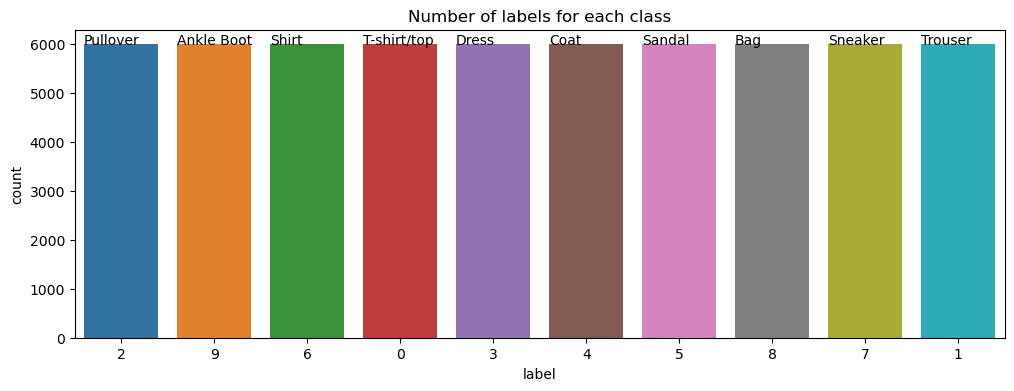

In [36]:
def plot_label_per_class(data):
    f, ax = plt.subplots(1,1, figsize=(12,4))
    g = sns.countplot(x=data.label, order=data["label"].value_counts().index)
    g.set_title("Number of labels for each class")

    for p, label in zip(g.patches, data["label"].value_counts().index):
        g.annotate(labels[label], (p.get_x(), p.get_height()+0.1))
    plt.show()  
    
plot_label_per_class(train_data)

Test հավաքածու պատկերների դասի բաշխում

In [37]:
get_classes_distribution(test_data)

T-shirt/top         :   1000 or 10.0%
Trouser             :   1000 or 10.0%
Pullover            :   1000 or 10.0%
Dress               :   1000 or 10.0%
Bag                 :   1000 or 10.0%
Shirt               :   1000 or 10.0%
Sandal              :   1000 or 10.0%
Coat                :   1000 or 10.0%
Sneaker             :   1000 or 10.0%
Ankle Boot          :   1000 or 10.0%


Նաև թեստային հավաքածուում 10 դասերը հավասարապես բաշխված են (յուրաքանչյուրը 10%):

Եկեք նաև գծագրենք դասի բաշխումը:

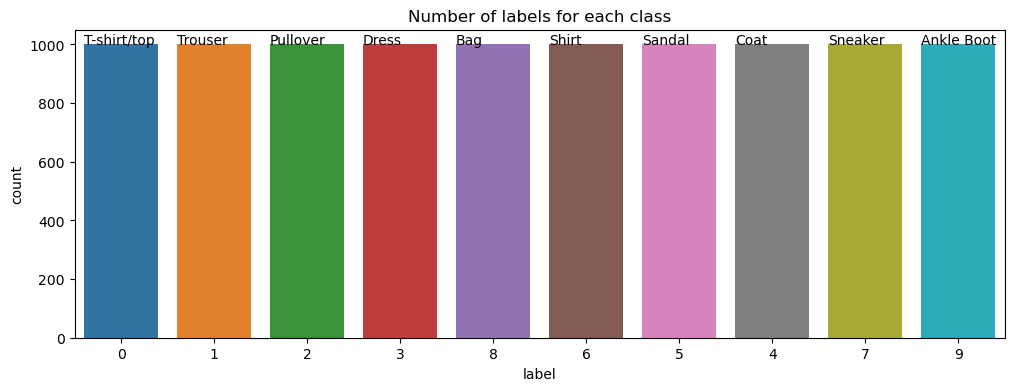

In [38]:
plot_label_per_class(test_data)

## <a id="42">Sample images (Նմուշների պատկերներ)</a>
**Train հավաքածուի նկարներ**

Եկեք որոշ նմուշներ գծենք պատկերների համար:

Մենք պիտակներ ենք ավելացնում train-ի հավաքածուի պատկերներին՝ համապատասխան նորաձևության իրերի կատեգորիայով:

In [39]:
def sample_images_data(data):
    # An empty list to collect some samples
    sample_images = []
    sample_labels = []

    # Iterate over the keys of the labels dictionary defined in the above cell
    for k in labels.keys():
        # Get four samples for each category
        samples = data[data["label"] == k].head(4)
        # Append the samples to the samples list
        for j, s in enumerate(samples.values):
            # First column contain labels, hence index should start from 1
            img = np.array(samples.iloc[j, 1:]).reshape(IMG_ROWS,IMG_COLS)
            sample_images.append(img)
            sample_labels.append(samples.iloc[j, 0])

    print("Total number of sample images to plot:", len(sample_images))
    return sample_images, sample_labels

train_sample_images, train_sample_labels = sample_images_data(train_data)

Total number of sample images to plot: 40


Հիմա եկեք գծենք պատկերները:

Պիտակները ցուցադրված են յուրաքանչյուր նկարի վերևում:

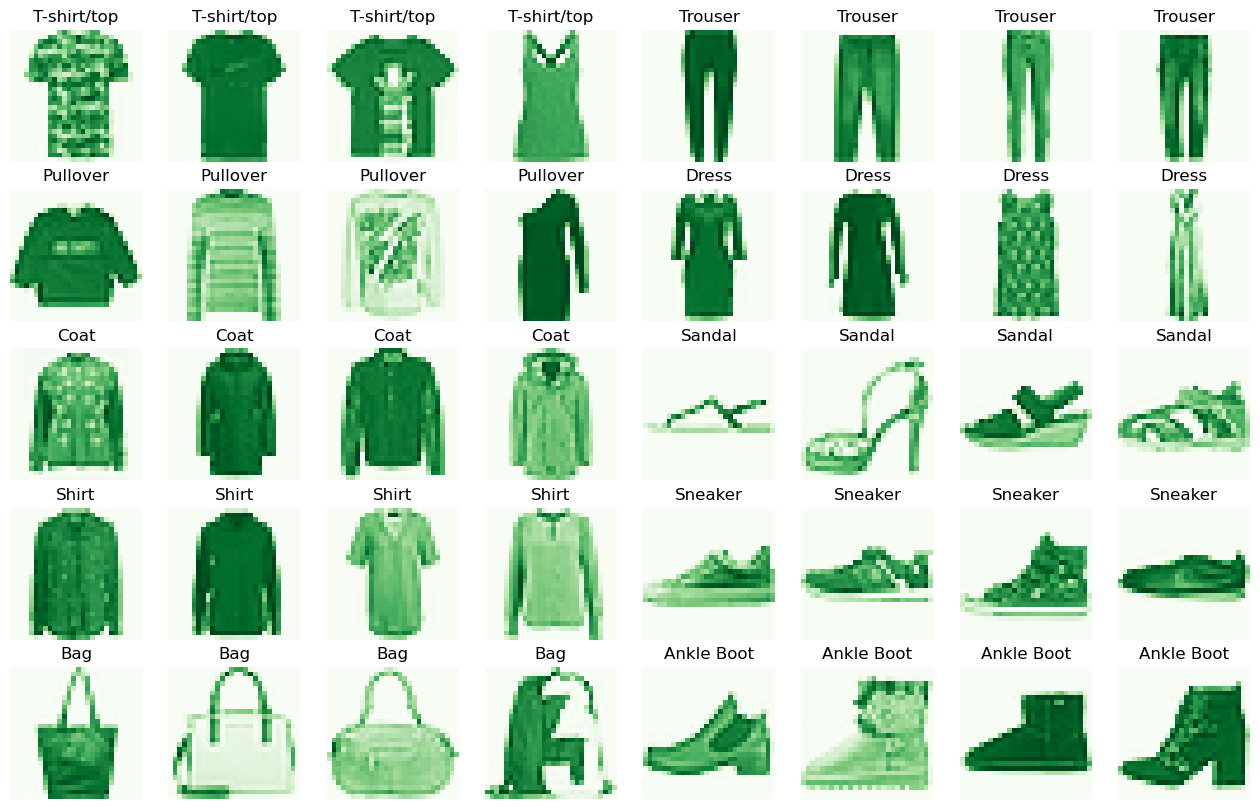

In [40]:
def plot_sample_images(data_sample_images,data_sample_labels,cmap="Blues"):
    # Plot the sample images now
    f, ax = plt.subplots(5,8, figsize=(16,10))

    for i, img in enumerate(data_sample_images):
        ax[i//8, i%8].imshow(img, cmap=cmap)
        ax[i//8, i%8].axis('off')
        ax[i//8, i%8].set_title(labels[data_sample_labels[i]])
    plt.show()    
    
plot_sample_images(train_sample_images,train_sample_labels, "Greens")

**Test հավաքածու նկարներ**

Եկեք հիմա գծենք թեստային հավաքածուի պատկերների ընտրություն:

Պիտակներ նույնպես ավելացված են (դրանք հայտնի են):

Total number of sample images to plot: 40


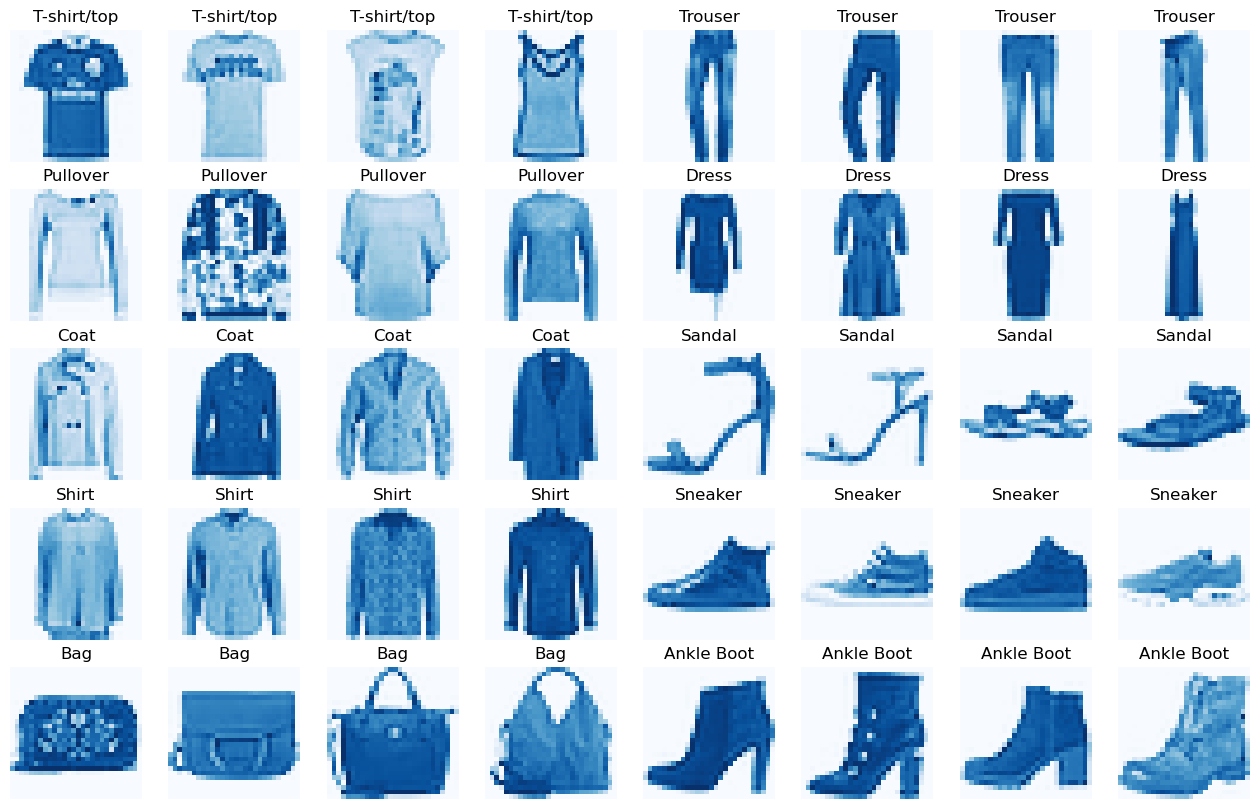

In [41]:
test_sample_images, test_sample_labels = sample_images_data(test_data)

plot_sample_images(test_sample_images,test_sample_labels)

# <a id="5">Model</a>
Մենք սկսում ենք մոդելի պատրաստումից:

## <a id="51">Մոդելի պատրաստում</a>

### Տվյալների նախապատրաստում

Նախ մենք կկատարենք տվյալների նախնական մշակում՝ մոդելին պատրաստվելու համար:

Մենք վերափոխում ենք սյունակները (784)-ից (28,28,1): Մենք նաև պահպանում ենք պիտակի (նպատակային) հատկանիշը որպես առանձին վեկտոր:

In [42]:
# data preprocessing
def data_preprocessing(raw):
    out_y = to_categorical(raw.label, NUM_CLASSES)
    num_images = raw.shape[0]
    x_as_array = raw.values[:,1:]
    x_shaped_array = x_as_array.reshape(num_images, IMG_ROWS, IMG_COLS, 1)
    out_x = x_shaped_array / 255
    return out_x, out_y


Մենք մշակում ենք և՛ train_data, և՛ test_data

In [43]:
# prepare the data
X, y = data_preprocessing(train_data)
X_test, y_test = data_preprocessing(test_data)

**Split (պառակտել) train-ը train և validation (վավերացում) հավաքածուներում**

Մենք հետագայում բաժանեցինք train-ի հավաքածուն train-ի և վավերացման հավաքածուի: Վավերացման հավաքածուն կկազմի սկզբնական train-ի հավաքածուի 20%-ը, հետևաբար բաժանումը կլինի train/validation 0,8/0,2:

In [44]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

Վերամշակված train-ի չափերը, validation-ը և test հավաքածուն հետևյալն են.

In [45]:
print("Fashion MNIST train -  rows:",X_train.shape[0]," columns:", X_train.shape[1:4])
print("Fashion MNIST valid -  rows:",X_val.shape[0]," columns:", X_val.shape[1:4])
print("Fashion MNIST test -  rows:",X_test.shape[0]," columns:", X_test.shape[1:4])

Fashion MNIST train -  rows: 48000  columns: (28, 28, 1)
Fashion MNIST valid -  rows: 12000  columns: (28, 28, 1)
Fashion MNIST test -  rows: 10000  columns: (28, 28, 1)


Եկեք ստուգենք դասի անհավասարակշռությունը ստացված վերապատրաստման հավաքածուի համար:

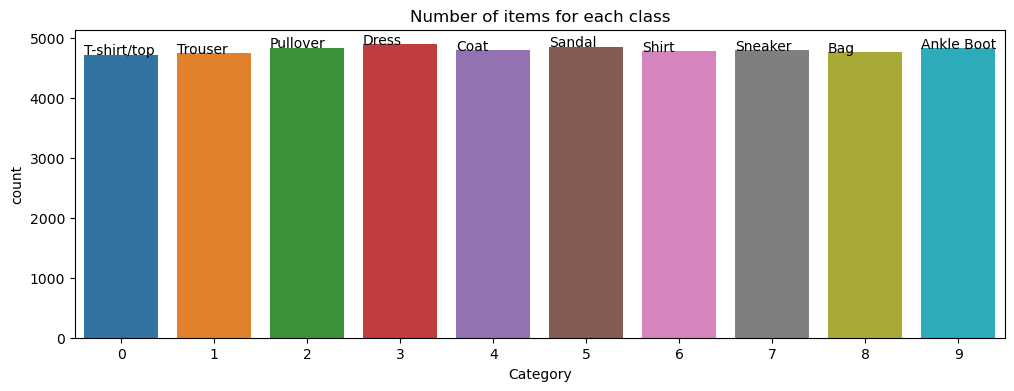

Dress               :   4891 or 10.189583333333333%
Sandal              :   4855 or 10.114583333333334%
Pullover            :   4836 or 10.075000000000001%
Ankle Boot          :   4827 or 10.05625%
Sneaker             :   4798 or 9.995833333333334%
Coat                :   4796 or 9.991666666666667%
Shirt               :   4779 or 9.95625%
Bag                 :   4757 or 9.910416666666666%
Trouser             :   4745 or 9.885416666666668%
T-shirt/top         :   4716 or 9.825000000000001%


In [46]:
def plot_count_per_class(yd):
    ydf = pd.DataFrame(yd)
    f, ax = plt.subplots(1,1, figsize=(12,4))
    g = sns.countplot(x=ydf[0], order=np.arange(0,10))
    g.set_title("Number of items for each class")
    g.set_xlabel("Category")
    
    for p, label in zip(g.patches, np.arange(0,10)):
        g.annotate(labels[label], (p.get_x(), p.get_height()+0.1))
        
    plt.show()  

def get_count_per_class(yd):
    ydf = pd.DataFrame(yd)
    # Get the count for each label
    label_counts = ydf[0].value_counts()

    # Get total number of samples
    total_samples = len(yd)

    # Count the number of items in each class
    for i in range(len(label_counts)):
        label = labels[label_counts.index[i]]
        count = label_counts.values[i]
        percent = (count / total_samples) * 100
        print("{:<20s}:   {} or {}%".format(label, count, percent))
    
plot_count_per_class(np.argmax(y_train,axis=1))
get_count_per_class(np.argmax(y_train,axis=1))

Եվ նաև վավերացման հավաքածուի համար:

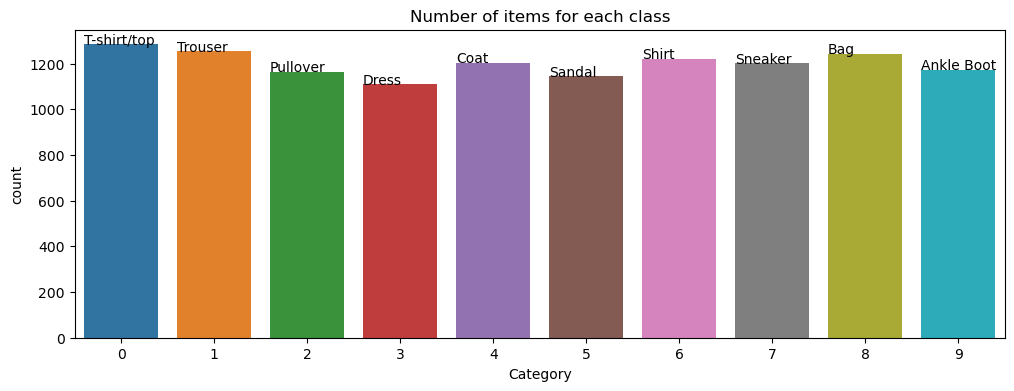

T-shirt/top         :   1284 or 10.7%
Trouser             :   1255 or 10.458333333333334%
Bag                 :   1243 or 10.358333333333333%
Shirt               :   1221 or 10.174999999999999%
Coat                :   1204 or 10.033333333333333%
Sneaker             :   1202 or 10.016666666666667%
Ankle Boot          :   1173 or 9.775%
Pullover            :   1164 or 9.700000000000001%
Sandal              :   1145 or 9.541666666666666%
Dress               :   1109 or 9.241666666666665%


In [47]:
plot_count_per_class(np.argmax(y_val,axis=1))
get_count_per_class(np.argmax(y_val,axis=1))

Ե՛վ train-ը, և՛ validation հավաքածուն անհավասարակշիռ են դասերի բաշխման առումով:

## <a id="52">Train the model (մոդելի պարապմունք)</a>

**Build the model**

Մենք կօգտագործենք **Sequential (հաջորդական)** մոդելը:

- **Sequential** մոդելը շերտերի գծային կույտ է: Այն կարող է նախ սկզբնավորվել, այնուհետև մենք ավելացնում ենք շերտերը՝ օգտագործելով **add** մեթոդը կամ կարող ենք ավելացնել բոլոր շերտերը սկզբնական փուլում: Ավելացված շերտերը հետևյալն են.

- **Conv2D-ը** 2D Convolutional շերտ է (այսինքն՝ տարածական ոլորում պատկերների վրա): Օգտագործված պարամետրերն են.

    - ֆիլտրեր - այս շերտի հետ օգտագործվող ֆիլտրերի (Kernels) քանակը. այստեղ ֆիլտրեր = 32;
    - kernel_size - Kernel-ի չափսը՝ (3 x 3);
    - activation - ակտիվացման գործառույթն է, որն օգտագործվում է, այս դեպքում `relu`;
    - kernel_initializer - ֆունկցիա, որն օգտագործվում է Kernel-ի սկզբնավորման համար;
    - input_shape - CNN-ին ներկայացված պատկերի ձևն է. մեր դեպքում 28 x 28 է **Conv2D-ի** մուտքն ու ելքը 4D թենզոր է:

- **MaxPooling2D-ը** տարածական տվյալների առավելագույն միավորման գործողություն է: Այստեղ օգտագործվող պարամետրերն են.

    - pool_size, այս դեպքում (2,2), որը ներկայացնում է այն գործոնները, որոնցով կրճատվում են երկու ուղղություններով.

    - **Conv2D** հետևյալ պարամետրերով.

    - ֆիլտրեր՝ 64;
    - Kernel-ի չափը՝ (3 x 3);
    - activation: `relu`;

- **MaxPooling2D** պարամետրով.

    - pool_size : (2,2);

- **Conv2D** հետևյալ պարամետրերով.

    - ֆիլտրեր՝ 128;
    - միջուկի չափը՝ (3 x 3);
    - ակտիվացում: `relu`;
- **Flatten**։ Այս շերտը հարթեցնում է մուտքը: Չի ազդում խմբաքանակի չափի վրա: Այն օգտագործվում է առանց պարամետրերի;

- **Dense**. Այս շերտը սովորական ամբողջությամբ միացված NN շերտ է: Այն օգտագործվում է առանց պարամետրերի;

    - unit-ներ - սա դրական ամբողջ թիվ է, որը նշանակում է. այս դեպքում՝ 128;
    - activation - ակտիվացման գործառույթ : `relu`;
- **Dense**. Սա վերջնական շերտն է (լիովին միացված): Այն օգտագործվում է պարամետրերով.

    - unit-ներ՝ դասերի քանակը (մեր դեպքում՝ 10);
    - activation: `softmax`; Այս վերջնական շերտի համար օգտագործվում է softmax ակտիվացում (բազմադաս դասակարգման ստանդարտ)
Այնուհետև մենք կազմում ենք մոդելը՝ նշելով նաև հետևյալ պարամետրերը.

- *loss (կորուստ)*;
- *optimizer (օպտիմիզատոր)*;
- *metrics (չափումներ)*.

In [48]:
# Model
model = Sequential()
# Add convolution 2D
model.add(Conv2D(32, kernel_size=(3, 3),
                 activation='relu',
                 kernel_initializer='he_normal',
                 input_shape=(IMG_ROWS, IMG_COLS, 1)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, 
                 kernel_size=(3, 3), 
                 activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(NUM_CLASSES, activation='softmax'))


model.compile(loss=keras.losses.categorical_crossentropy,
              optimizer='adam',
              metrics=['accuracy'])

**Մոդելի ստուգում**

Եկեք ստուգենք մոդելը, որը մենք ինիթիալիզացրել ենք (initialized)։

In [49]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 3, 3, 128)         73856     
                                                                 
 flatten (Flatten)           (None, 1152)              0

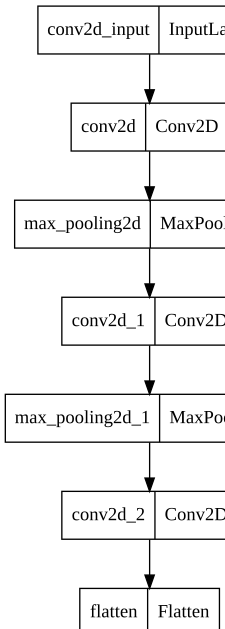

In [50]:
plot_model(model, to_file='first-model.png')
SVG(model_to_dot(model).create(prog='dot', format='svg'))

**Մոդելի աշխատացում**

Մոդելը աշխատացնում ենք train-ի հավաքածուով։ Մենք նաև օգտագործում ենք validation հավաքածուն (ենթաբազմություն սկզբնական train հավաքածուից) վավերացման համար:

In [51]:
train_model = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=NO_EPOCHS,
    verbose=1,
    validation_data=(X_val, y_val)
)

Epoch 1/50


375/375 [==============================] - 34s 78ms/step - loss: 0.5292 - accuracy: 0.8074 - val_loss: 0.3875 - val_accuracy: 0.8553
Epoch 2/50
375/375 [==============================] - 45s 120ms/step - loss: 0.3374 - accuracy: 0.8779 - val_loss: 0.3586 - val_accuracy: 0.8681
Epoch 3/50
375/375 [==============================] - 34s 92ms/step - loss: 0.2879 - accuracy: 0.8940 - val_loss: 0.2960 - val_accuracy: 0.8967
Epoch 4/50
375/375 [==============================] - 32s 86ms/step - loss: 0.2531 - accuracy: 0.9088 - val_loss: 0.2960 - val_accuracy: 0.8929
Epoch 5/50
375/375 [==============================] - 29s 77ms/step - loss: 0.2239 - accuracy: 0.9183 - val_loss: 0.2564 - val_accuracy: 0.9075
Epoch 6/50
375/375 [==============================] - 29s 78ms/step - loss: 0.2046 - accuracy: 0.9235 - val_loss: 0.2706 - val_accuracy: 0.9038
Epoch 7/50
375/375 [==============================] - 28s 74ms/step - loss: 0.1846 - accuracy: 0.9310 - val_loss: 0.2608 - val_accura

## <a id="53">Թեստի կանխատեսման ճշգրտությունը</a>

Մենք հաշվարկում ենք թեստի կորուստը և ճշգրտությունը:

In [52]:
score = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.7139914631843567
Test accuracy: 0.9151999950408936


Փորձարկման ճշգրտությունը մոտ 0,915 է:

Մենք գնահատեցինք մոդելի ճշգրտությունը՝ հիմնվելով թեստային հավաքածուի համար կանխատեսված արժեքների վրա: Եկեք ստուգենք վավերացման արժեքը վերապատրաստման ընթացքում:

## <a id="54">Վավերացման ճշգրտություն և կորուստ</a>

Եկեք գծագրենք train-ի և validation-ի ճշգրտությունը և կորուստը training-ի պատմությունից:

In [53]:
def create_trace(x,y,ylabel,color):
        trace = go.Scatter(
            x = x,y = y,
            name=ylabel,
            marker=dict(color=color),
            mode = "markers+lines",
            text=x
        )
        return trace
    
def plot_accuracy_and_loss(train_model):
    hist = train_model.history
    acc = hist['accuracy']
    val_acc = hist['val_accuracy']
    loss = hist['loss']
    val_loss = hist['val_loss']
    epochs = list(range(1,len(acc)+1))
    
    trace_ta = create_trace(epochs,acc,"Training accuracy", "Green")
    trace_va = create_trace(epochs,val_acc,"Validation accuracy", "Red")
    trace_tl = create_trace(epochs,loss,"Training loss", "Blue")
    trace_vl = create_trace(epochs,val_loss,"Validation loss", "Magenta")
   
    fig = tools.make_subplots(rows=1,cols=2, subplot_titles=('Training and validation accuracy',
                                                             'Training and validation loss'))
    fig.append_trace(trace_ta,1,1)
    fig.append_trace(trace_va,1,1)
    fig.append_trace(trace_tl,1,2)
    fig.append_trace(trace_vl,1,2)
    fig['layout']['xaxis'].update(title = 'Epoch')
    fig['layout']['xaxis2'].update(title = 'Epoch')
    fig['layout']['yaxis'].update(title = 'Accuracy', range=[0,1])
    fig['layout']['yaxis2'].update(title = 'Loss', range=[0,1])

    
    iplot(fig, filename='accuracy-loss')

plot_accuracy_and_loss(train_model)

c:\Users\user\anaconda3\lib\site-packages\plotly\tools.py:460: DeprecationWarning:

plotly.tools.make_subplots is deprecated, please use plotly.subplots.make_subplots instead



Վավերացման ճշգրտությունը չի բարելավվում մի քանի դարաշրջանից հետո, իսկ վավերացման կորուստը մեծանում է մի քանի դարաշրջանից հետո: Սա հաստատում է մեր այն ենթադրությունը, որ մոդելը գերհագեցված է: Մենք կփորձենք բարելավել մոդելը՝ ավելացնելով Dropout շերտերը:

## <a id="55">Մոդելին Dropout շերտերի ավելացում</a>

Մենք մոդելին ավելացնում ենք մի քանի «Dropout» շերտեր, որոնք կօգնեն խուսափել ավելորդ տեղադրումից:

Droupout-ը օգնում է խուսափել չափից ավելի overfitting-ի մի քանի առումներով:

In [54]:
# Model
model = Sequential()
# Add convolution 2D
model.add(Conv2D(32, kernel_size=(3, 3),
                 activation='relu',
                 kernel_initializer='he_normal',
                 input_shape=(IMG_ROWS, IMG_COLS, 1)))
model.add(MaxPooling2D((2, 2)))
# Add dropouts to the model
model.add(Dropout(0.25))
model.add(Conv2D(64, 
                 kernel_size=(3, 3), 
                 activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add dropouts to the model
model.add(Dropout(0.25))
model.add(Conv2D(128, (3, 3), activation='relu'))
# Add dropouts to the model
model.add(Dropout(0.4))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
# Add dropouts to the model
model.add(Dropout(0.3))
model.add(Dense(NUM_CLASSES, activation='softmax'))


model.compile(loss=keras.losses.categorical_crossentropy,
              optimizer='adam',
              metrics=['accuracy'])

## <a id="56">Մոդելի վերապատրաստում</a>

Եկեք սկզբից նայենք մոդելի տեսքին

In [55]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 dropout (Dropout)           (None, 13, 13, 32)        0         
                                                                 
 conv2d_4 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 5, 5, 64)         

Նաև գծագրենք մոդելի տեսքը

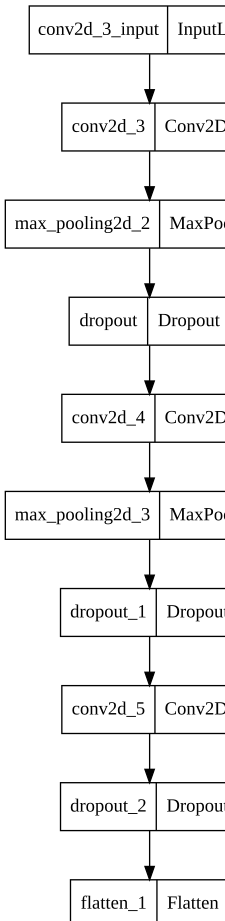

In [56]:
plot_model(model, to_file='second-model.png')
SVG(model_to_dot(model).create(prog='dot', format='svg'))

Եվ հիմա եկեք աշխատացնենք նոր մոդելը

In [57]:
train_model = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=NO_EPOCHS,
    verbose=1,
    validation_data=(X_val, y_val)
)

Epoch 1/50
375/375 [==============================] - 41s 96ms/step - loss: 0.7910 - accuracy: 0.7044 - val_loss: 0.4960 - val_accuracy: 0.8117
Epoch 2/50
375/375 [==============================] - 34s 90ms/step - loss: 0.5021 - accuracy: 0.8147 - val_loss: 0.3968 - val_accuracy: 0.8559
Epoch 3/50
375/375 [==============================] - 34s 90ms/step - loss: 0.4336 - accuracy: 0.8397 - val_loss: 0.3426 - val_accuracy: 0.8764
Epoch 4/50
375/375 [==============================] - 34s 90ms/step - loss: 0.3968 - accuracy: 0.8551 - val_loss: 0.3207 - val_accuracy: 0.8815
Epoch 5/50
375/375 [==============================] - 33s 88ms/step - loss: 0.3633 - accuracy: 0.8673 - val_loss: 0.3110 - val_accuracy: 0.8888
Epoch 6/50
375/375 [==============================] - 34s 91ms/step - loss: 0.3447 - accuracy: 0.8733 - val_loss: 0.2925 - val_accuracy: 0.8969
Epoch 7/50
375/375 [==============================] - 38s 102ms/step - loss: 0.3279 - accuracy: 0.8794 - val_loss: 0.2803 - val_accuracy

## <a id="57">Վավերացման ճշգրտության և կորուստի ստուգումը նոր մոդելով</a>

Եկեք վերագնահատենք կանխատեսման ճշգրտությունը նոր մոդելի հետ:

In [58]:
plot_accuracy_and_loss(train_model)

Dropout շերտերն ավելացնելուց հետո վավերացման ճշգրտությունը և վավերացման կորուստը շատ ավելի լավն են: Այժմ ստուգենք թեստային հավաքածուի կանխատեսումը:

## <a id="58">Կանխատեսման ճշգրտությունը նոր մոդելի հետ</a>

Եկեք վերապատրաստենք թեստի կանխատեսման ճշգրտությունը նոր մոդելի հետ։

In [59]:
score = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.20334060490131378
Test accuracy: 0.9283000230789185


Նաև բարելավվել է թեստի ճշգրտությունը: Փորձարկման ճշգրտությունն այժմ մոտավորապես 0,928 է:

In [ ]:
# Save the trained model so predict.py can use it without retraining
os.makedirs("model", exist_ok=True)
model.save("model/fashion_cnn.keras")

In [60]:
#get the predictions for the test data
predicted_test = model.predict(X_test)
predicted_classes = predicted_test.argmax(axis=-1)
#get the indices to be plotted
y_true = test_data.iloc[:, 0]

313/313 [==============================] - 4s 9ms/step


In [61]:
correct_indices = np.where(predicted_classes == y_true)[0]
incorrect_indices = np.where(predicted_classes != y_true)[0]

correct_images = X_test[correct_indices]
incorrect_images = X_test[incorrect_indices]

In [62]:
correct_probabilities = predicted_test[correct_indices]
incorrect_probabilities = predicted_test[incorrect_indices]
correct_labels = y_true[correct_indices]
incorrect_labels = y_true[incorrect_indices]

print("Correct predicted classes:",correct_images.shape[0])
print("Incorrect predicted classes:",incorrect_images.shape[0])

Correct predicted classes: 9283
Incorrect predicted classes: 717


In [63]:
target_names = [
    "Class {} ({}) :".format(i,labels[i]) 
        for i in range(NUM_CLASSES)
]
print(classification_report(y_true, predicted_classes, target_names=target_names))

                         precision    recall  f1-score   support

Class 0 (T-shirt/top) :       0.90      0.88      0.89      1000
    Class 1 (Trouser) :       0.99      0.99      0.99      1000
   Class 2 (Pullover) :       0.87      0.89      0.88      1000
      Class 3 (Dress) :       0.92      0.95      0.94      1000
       Class 4 (Coat) :       0.90      0.88      0.89      1000
     Class 5 (Sandal) :       1.00      0.97      0.98      1000
      Class 6 (Shirt) :       0.80      0.80      0.80      1000
    Class 7 (Sneaker) :       0.96      0.97      0.96      1000
        Class 8 (Bag) :       0.98      0.99      0.99      1000
 Class 9 (Ankle Boot) :       0.97      0.97      0.97      1000

               accuracy                           0.93     10000
              macro avg       0.93      0.93      0.93     10000
           weighted avg       0.93      0.93      0.93     10000



Լավագույն ճշգրտությունը ստացվում է 1-ին, 5-րդ, 8-րդ, 9-րդ և 7-րդ դասի համար: Վատագույն ճշգրտությունը 6-րդ դասի համար է:

Հետկանչումն ամենաբարձրն է 8-րդ, 5-րդ դասի համար և ամենափոքրը՝ 6-րդ և 4-րդ դասի համար:

f1-ն ամենաբարձրն է 1-ին, 5-րդ և 8-րդ դասի համար, իսկ ամենափոքրը՝ 6-րդ դասի համար, որին հաջորդում են 4-րդ և 2-րդ դասերը:

Եկեք ստուգենք նաև որոշ պատկերներ: Մենք ստեղծեցինք կանխատեսված պատկերների հավաքածուի երկու ենթաբազմություն՝ ճիշտ և սխալ դասակարգված:

# <a id="6">Դասակարգված պատկերների վիզուալիզացիան</a>

## <a id="61">Ճիշտ դասակարգված պատկերներ</a>

Մենք պատկերացնում ենք մի քանի պատկերներ, որոնք ճիշտ դասակարգված են:

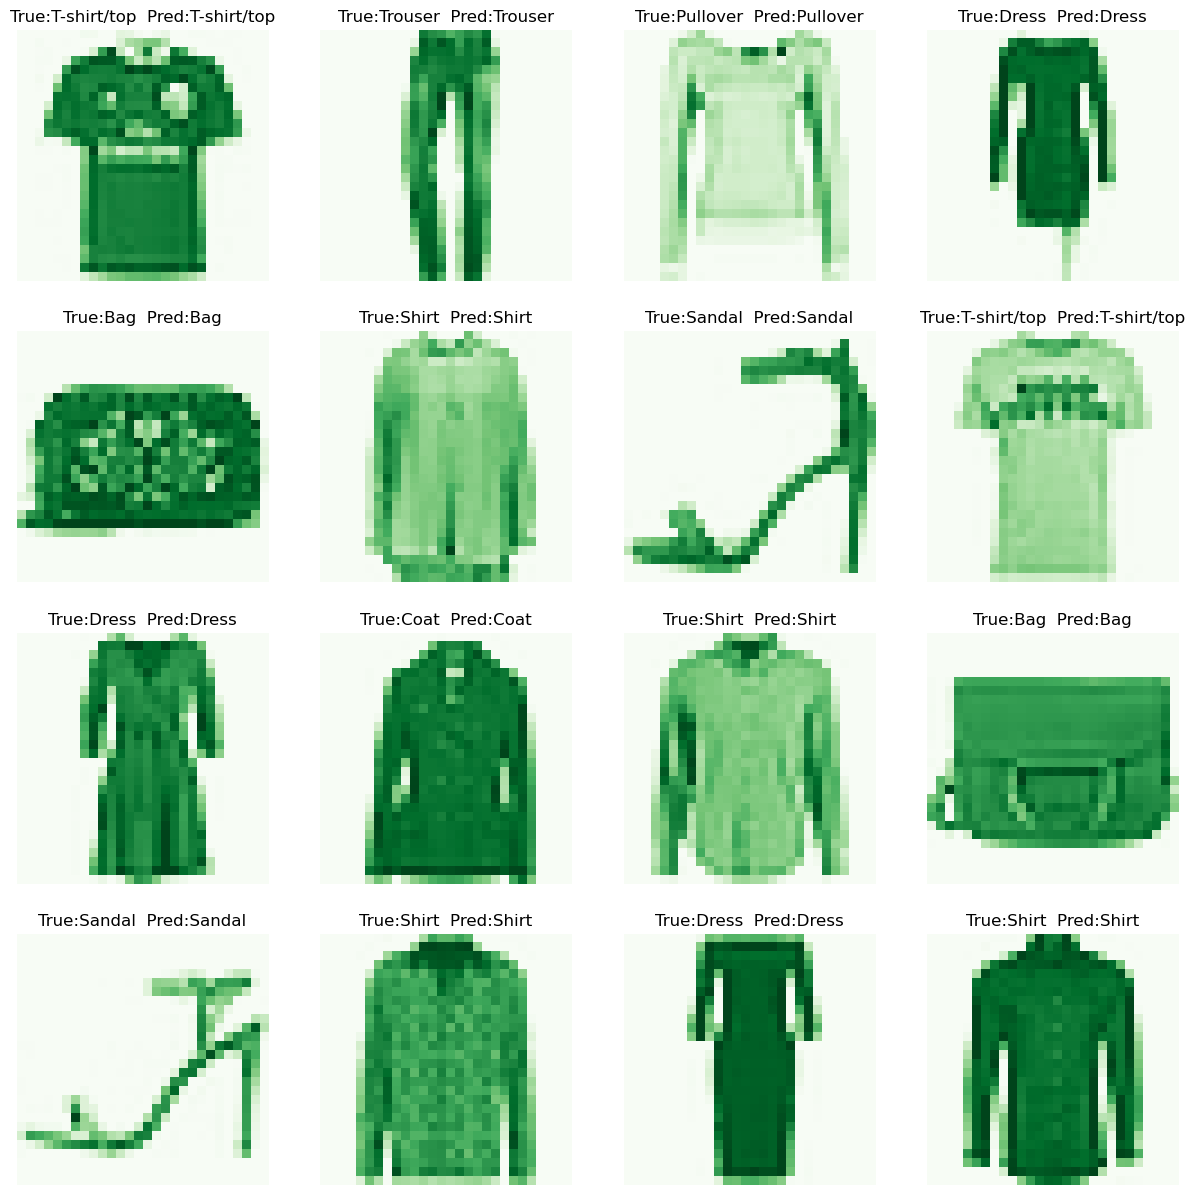

In [64]:
def plot_images(data_index,cmap="Blues"):
    # Plot the sample images now
    f, ax = plt.subplots(4,4, figsize=(15,15))

    for i, indx in enumerate(data_index[:16]):
        ax[i//4, i%4].imshow(X_test[indx].reshape(IMG_ROWS,IMG_COLS), cmap=cmap)
        ax[i//4, i%4].axis('off')
        ax[i//4, i%4].set_title("True:{}  Pred:{}".format(labels[y_true[indx]],labels[predicted_classes[indx]]))
    plt.show()    
    
plot_images(correct_indices, "Greens")

## <a id="62">Սխալ դասակարգված պատկերներ</a>

Տեսնենք նաև մի քանի պատկերներ, որոնք սխալ դասակարգված են:

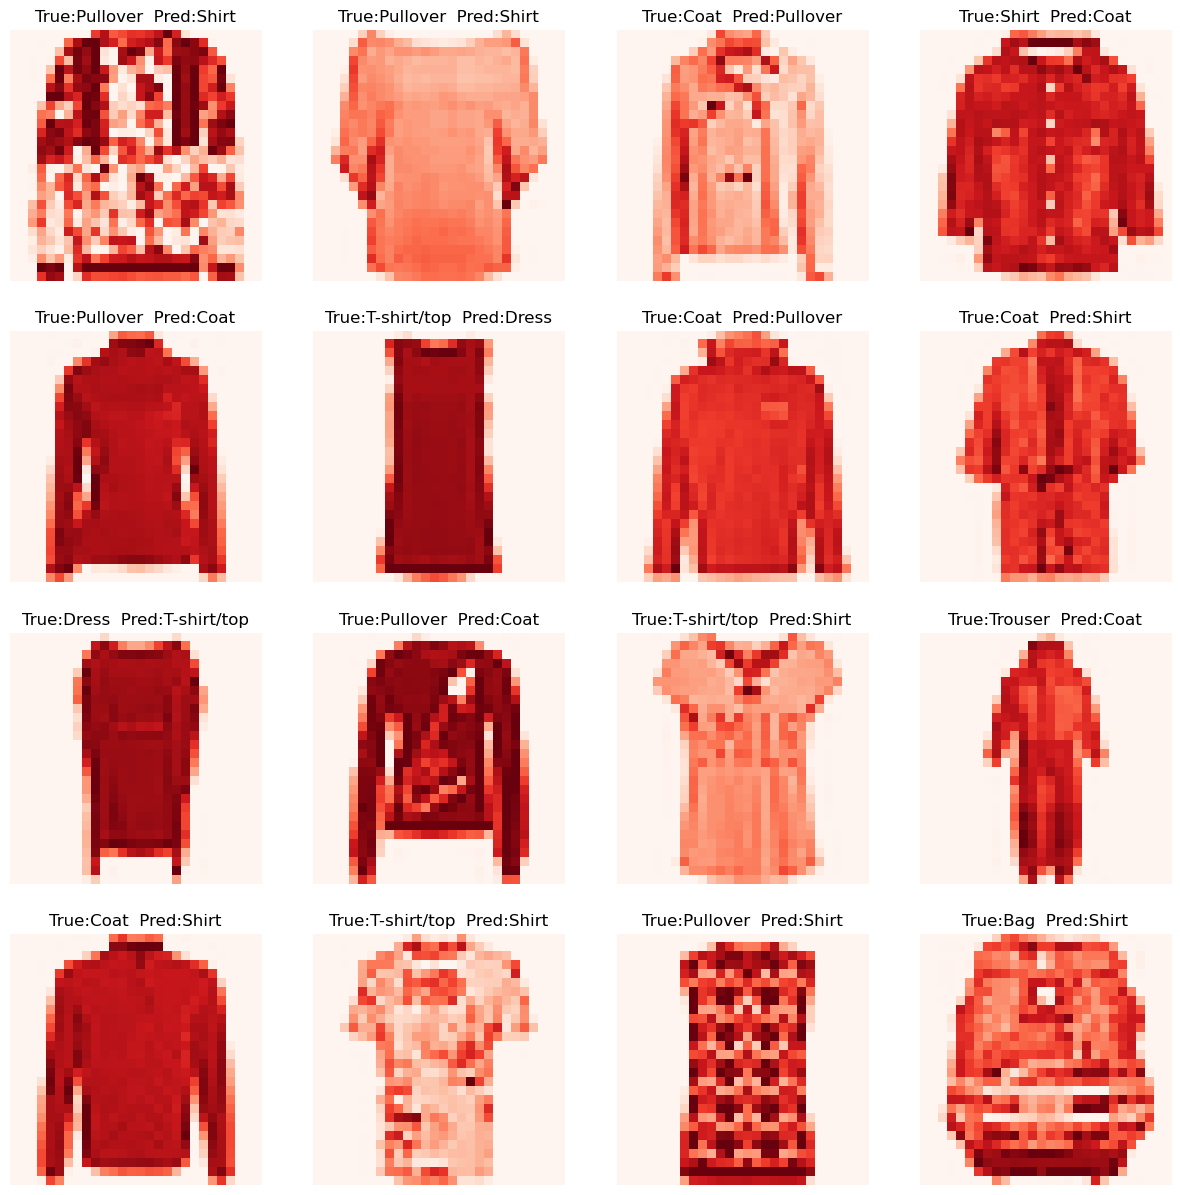

In [65]:
plot_images(incorrect_indices, "Reds")

# <a id="7">Եզրակացություն</a>

Բազմաթիվ ոլորման շերտերով և ուսուցման համար 50 epoch-ներով բարդ հաջորդական մոդելով մենք ստացանք ~0,91 ճշգրտություն թեստային կանխատեսման համար: Վավերացման ճշգրտությունը և կորուստը ուսումնասիրելուց հետո մենք հասկացանք, որ մոդելը չափազանց հարմարեցված է:

Մենք վերապատրաստեցինք մոդելը Dropout-ի շերտերով դեպի մոդել՝ չափից ավելի հարմարեցումը նվազեցնելու համար:

Մենք հաստատեցինք մոդելի կատարելագործումը և նույն թվով դարաշրջաններով ուսուցման համար մենք ստացանք նոր մոդելով ~0,93 ճշգրտություն թեստային կանխատեսման համար: Միայն մի քանի դասեր են ճիշտ դասակարգված անընդհատ, հատկապես դաս 6 (շապիկ) և դաս 2 (փուլովեր):

# <a id="8">Հղումներ</a>

[1] Fashion MNIST, An MNIST-like dataset of 70,000 28x28 labeled fashion images, https://www.kaggle.com/zalando-research/fashionmnist

[2] DanB, CollinMoris, Deep Learning From Scratch, https://www.kaggle.com/dansbecker/deep-learning-from-scratch

[3] DanB, Dropout and Strides for Larger Models, https://www.kaggle.com/dansbecker/dropout-and-strides-for-larger-models

[4] BGO, CNN with Keras, https://www.kaggle.com/bugraokcu/cnn-with-keras

[5] NAIN, EagerFMINST, https://www.kaggle.com/aakashnain/eagerfmnist

[6] Why Dropounts prevent overfitting in Deep Neural Networks, https://medium.com/@vivek.yadav/why-dropouts-prevent-overfitting-in-deep-neural-networks-937e2543a701

[7] Dropout: A Simple Way to Prevent Neural Networks from Overfitting, https://www.cs.toronto.edu/~hinton/absps/JMLRdropout.pdf

[8] Gabriel Preda, CNN with Tensorflow|Keras for Fashion MNIST (the main base for this notebook), https://www.kaggle.com/code/gpreda/cnn-with-tensorflow-keras-for-fashion-mnist
